# Vertex selection for taus: analysis notebook

Main working notebook. Day 1 goal: **define what we evaluate and what "correct" means, then reproduce the
first-look ΣpT² numbers with my own code.**

Day-1 tasks (each with a check):
1. **Tau selection**: truth hadronic taus from the γ*, visible pT > 20 GeV, |η| < 2.5, matched to a reco jet
   (ΔR < 0.2, jet pT > 20 GeV). *Check*: counts per μ; matched fraction ≈ 0.97 at μ = 0 falling with μ (fig 7).
2. **Truth label**: which reco candidate vertex is the correct interaction vertex (majority-of-HS-tracks rule,
   purity > 50%). *Check*: ceiling ≈ 0.997 at μ = 0, ≈ 0.85 at μ = 200.
3. **ΣpT²**: per event, Σ pT² of each candidate's tracks, pick the max. *Check*: my Σ pT² equals Delphes'
   `rv_sumpt2`; efficiency reproduces 0.987 / … / 0.649 (event-level).
4. **Efficiency**: per tau, with Wilson errors, vs μ.

Rules: `truth_*` columns only **select** which taus are evaluated and **define labels**, never feed an
algorithm (`samples.assert_no_truth` guards model inputs). Once a function works, move it to a `.py` module in
`vtx/` with a test, so the notebook doesn't accumulate stale state.

In [2]:
import sys
from pathlib import Path

import awkward as ak
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))
from vtx import samples
# finished functions live in vtx/analysis.py (edit them there, then restart the kernel)
from vtx.analysis import (cut, select_taus, correct_vertex, wilson, efficiency, chosen_z,
                          sumpt2_choice, cone_tracks, tjva_v1, tjva_v2, tjva_andsumpt2)

pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
print("mu points:", samples.MUS, "| slices:", samples.SLICES)

mu points: (0, 30, 50, 100, 140, 200) | slices: ('A_m60_120', 'B_m120_300', 'C_m300')


## Load

Full production: 11 runs × 5,000 events per μ (`samples.load(mu)` loads all 55k and checks the count against
`runs.csv`). For development, `load_dev` loads one run (5,000 events of the 60–120 GeV slice), which is fast.
Load only the columns you need: tracks dominate the memory (~570 tracks/event at μ = 50, ~2,000 at μ = 200).

In [3]:
COLS = [
    # bookkeeping
    "event_id", "run_id", "slice", "mu_nominal", "xsec_pb",
    # reco tracks
    "trk_pt", "trk_eta", "trk_phi", "trk_dz", "trk_err_dz", "trk_d0", "trk_err_d0", "trk_charge", "trk_delphes_vtx",
    # reco candidate vertices (Delphes VertexFinder)
    "rv_index", "rv_z", "rv_err_z", "rv_ndf", "rv_sumpt2",
    # reco jets
    "jet_pt", "jet_eta", "jet_phi",
    # truth (selection + labels only)
    "trk_truth_vtx", "trk_truth_is_pu", "trk_truth_tau", "truth_hs_z", "truth_n_vtx",
    "truth_tau_vis_pt", "truth_tau_vis_eta", "truth_tau_vis_phi", "truth_tau_nprong",
    "truth_tau_leptonic", "truth_tau_from_hard",
]

def load_dev(mu, run=101, slice_="A_m60_120", columns=COLS):
    """One production run (5,000 events) at one mu, for fast development."""
    return ak.from_parquet(samples.SLIM / slice_ / f"run{run}_mu{mu}.parquet", columns=columns)

ev = {mu: load_dev(mu) for mu in (0, 50, 200)}
for mu, a in ev.items():
    print(f"mu={mu:3d}: {len(a)} events | tracks/event {ak.mean(ak.num(a.trk_pt)):6.0f} | "
          f"candidate vertices/event {ak.mean(ak.num(a.rv_z)):5.1f} | true interactions/event {np.mean(a.truth_n_vtx):5.1f}")

mu=  0: 5000 events | tracks/event     30 | candidate vertices/event   1.1 | true interactions/event   1.0
mu= 50: 5000 events | tracks/event    581 | candidate vertices/event  29.9 | true interactions/event  51.1
mu=200: 5000 events | tracks/event   2230 | candidate vertices/event 101.1 | true interactions/event 200.9


## Data structure reference

One row = one event. Columns are jagged lists: `a.trk_pt[i]` is the list of track pTs in event `i`.
Units: GeV, mm, radians.

| prefix | one entry per | fields | notes |
|---|---|---|---|
| `trk_` | reco track | `pt, eta, phi, charge, d0, dz, err_d0, err_dz, err_pt, ctgtheta` | `dz` = z of closest approach to the beamline (z0), `d0` = transverse impact parameter, both smeared |
| `trk_delphes_vtx` | reco track | index of the candidate vertex the vertex finder clustered the track into | matches `rv_index`; **−1 = in no vertex** (~7% of tracks) |
| `rv_` | candidate vertex | `index, z, err_z, ndf, sumpt2` | **stored sorted by `sumpt2`, not by index**: always join on `rv_index`, never on list position |
| `jet_` | reco jet (anti-kT R = 0.4, pT > 20) | `pt, eta, phi, mass` | built from calorimeter towers, so `jet_ncharged` is always 0 (ignore it); `jet_tautag` is Delphes' truth-assisted tau tag: don't use it as an input |
| `trk_truth_vtx` | reco track | which true interaction the track came from: **0 = collision of interest**, ≥ 1 = a pileup interaction | |
| `trk_truth_is_pu` | reco track | Delphes' pileup flag (1 = from a pileup interaction) | redundant with `trk_truth_vtx != 0`; the slimmer checks they agree |
| `trk_truth_tau` | reco track | index into this event's `truth_tau_*` lists if the track is a tau decay product, else −1 | |
| `truth_tau_` | true tau (final, decaying) | `vis_pt, vis_eta, vis_phi, vis_m, nprong, npi0, charge, leptonic, from_hard, decay_rxy, decay_dz` | `vis` = visible decay products (no neutrinos); `from_hard` = from the γ* (vs. rare heavy-flavour decays) |
| `truth_hs_z`, `truth_n_vtx`, `truth_vtx_*` | event / true interaction | true z of the collision of interest; number of true interactions | |
| bookkeeping | event | `event_id` (same hard scatter ⇒ same ID at every μ, use for the split), `run_id, slice, mu_nominal, xsec_pb, nev_run` | |

**The two links you'll use most:** track → candidate (`trk_delphes_vtx` ↔ `rv_index`) and track → truth
(`trk_truth_vtx == 0` means "from the collision of interest", `trk_truth_tau >= 0` means "from a tau decay").

## Quality cuts on events
Evaluated object = a truth hadronic tau from the γ* (visible pT > 20 GeV, |η| < 2.5) **with a reco jet** within
ΔR < 0.2 (jet pT > 20 GeV). Return something per tau (event index, tau index, matched jet index).

In [4]:
# cut(all, printing=False) moved to vtx/analysis.py (imported in the first cell)
data_cut = cut(load_dev(50), printing=True)

Num events before cuts: 5000
Num events after tau cuts: 1478
Num events after jet cut: 1209


In [5]:
# select_taus(all) (Claude's per-tau version of cut()) moved to vtx/analysis.py
data = load_dev(50)
taus = select_taus(data)
# check: same events as cut()
assert taus.event.nunique() == len(cut(data))
print(f"{len(taus)} evaluated taus in {taus.event.nunique()} events")
taus.head()

1366 evaluated taus in 1209 events


,event,tau,jet,jet_pt,jet_eta,jet_phi,tau_pt,nprong
0,3,1,2,42.418,-0.566,-2.614,50.358,3
1,7,1,0,42.571,1.373,2.340,34.370,1
2,21,0,0,23.944,0.159,-0.067,22.956,1
3,22,0,0,39.291,-0.327,0.838,27.000,1
4,30,0,0,32.947,-0.836,-1.379,41.417,1


## Truth labels
For each event: which `rv_index` is the correct interaction vertex (−1 if none passes the purity cut).

In [6]:
# correct_vertex(data, purity=0.5) moved to vtx/analysis.py (imported in the first cell)
# purity=0 is Sebastian's / THOR definition: the vertex with the most HS tracks, merged vertices allowed
label = correct_vertex(load_dev(50), purity=0)
print(f"events with no HS vertex: {ak.mean(label == -1):.4f}")

events with no HS vertex: 0.0154


## Sumpt2 efficiency vs μ
Per evaluated tau: correct if the chosen vertex equals the label (and the label exists). Report the ceiling
(fraction with a label) next to it. First-look targets (event-level, all slices): ceiling 0.997 / 0.976 / 0.963 /
0.926 / 0.896 / 0.850, ΣpT² 0.987 / 0.851 / 0.815 / 0.747 / 0.704 / 0.649 at μ = 0 / 30 / 50 / 100 / 140 / 200.

In [7]:
mu_all = [0,30,50,100,140,200]
# wilson(k, n) moved to vtx/analysis.py; efficiency(correct, weights) returns (eff, low, high) using it

In [8]:
sumpt2_effs = []
eff_conds = []
ceilings = []
htrk_effs = []

for mu in mu_all:
    data = samples.load(mu,slices=samples.SLICES,columns=COLS)
    data_cut = cut(data)
    best_vtx_label = correct_vertex(data_cut)
    htrk_eff = ak.mean(best_vtx_label==0) #arg 0 is trk with highest pt

    # get the vertex with highest sumpt2 
    top = ak.firsts(data_cut.rv_index[ak.argmax(data_cut.rv_sumpt2, axis=1, keepdims=True)])
    sumpt2_eff = ak.mean(ak.fill_none(best_vtx_label == top, False))
    frac_merge = ak.mean(best_vtx_label==-1)
    ceil = 1 - frac_merge

    sumpt2_effs.append(sumpt2_eff)
    ceilings.append(ceil)
    eff_conds.append(sumpt2_eff/ceil)
    htrk_effs.append(htrk_eff)
    print(f'mu = {mu}, sumpt2 efficiency = {sumpt2_eff:.3f}, ceiling = {1-frac_merge:.3f}')

plt.plot(mu_all,sumpt2_effs,linestyle='--',marker='o',label='sumpt2')
plt.plot(mu_all,htrk_effs,linestyle='-.',marker='o',label='hardest track')
plt.ylim(0.6,1.05)
plt.xlabel('mu')
plt.ylabel('efficiency')
plt.legend()

mu = 0, sumpt2 efficiency = 0.987, ceiling = 0.997
mu = 30, sumpt2 efficiency = 0.875, ceiling = 0.998


KeyboardInterrupt: 

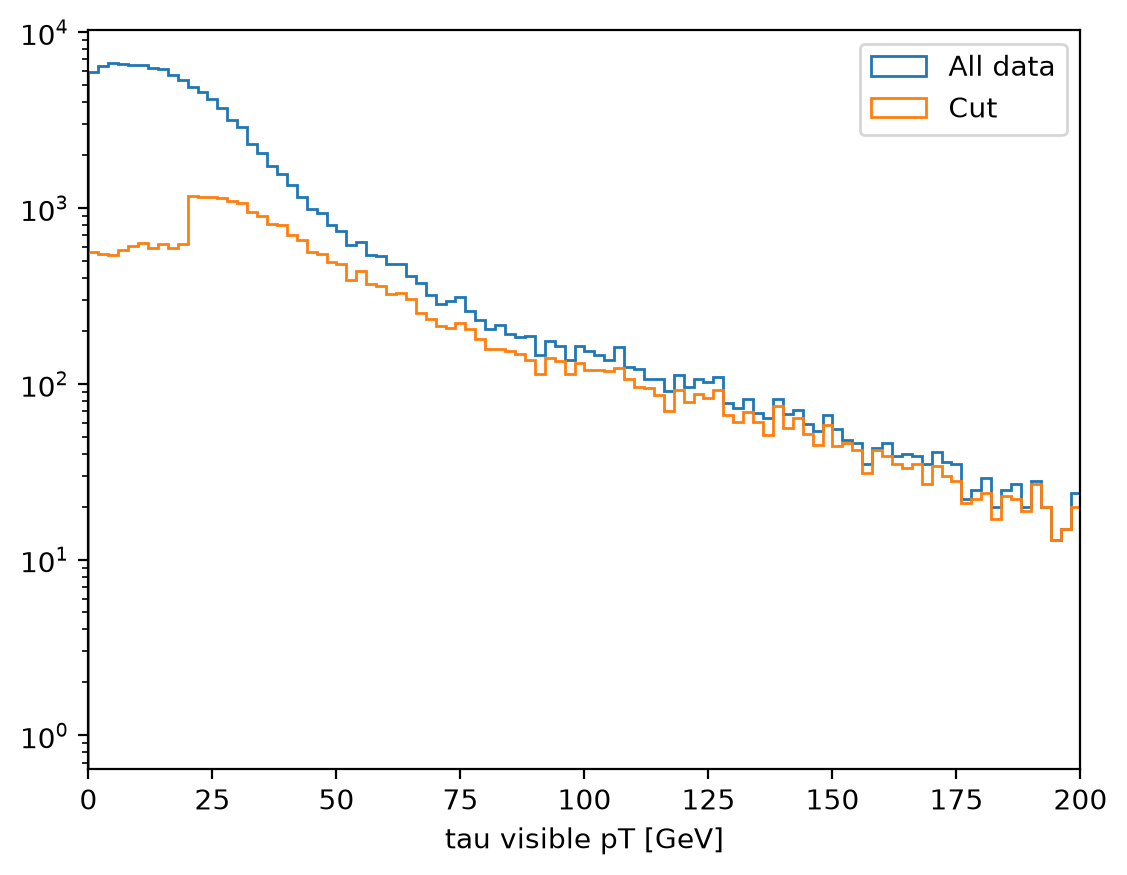

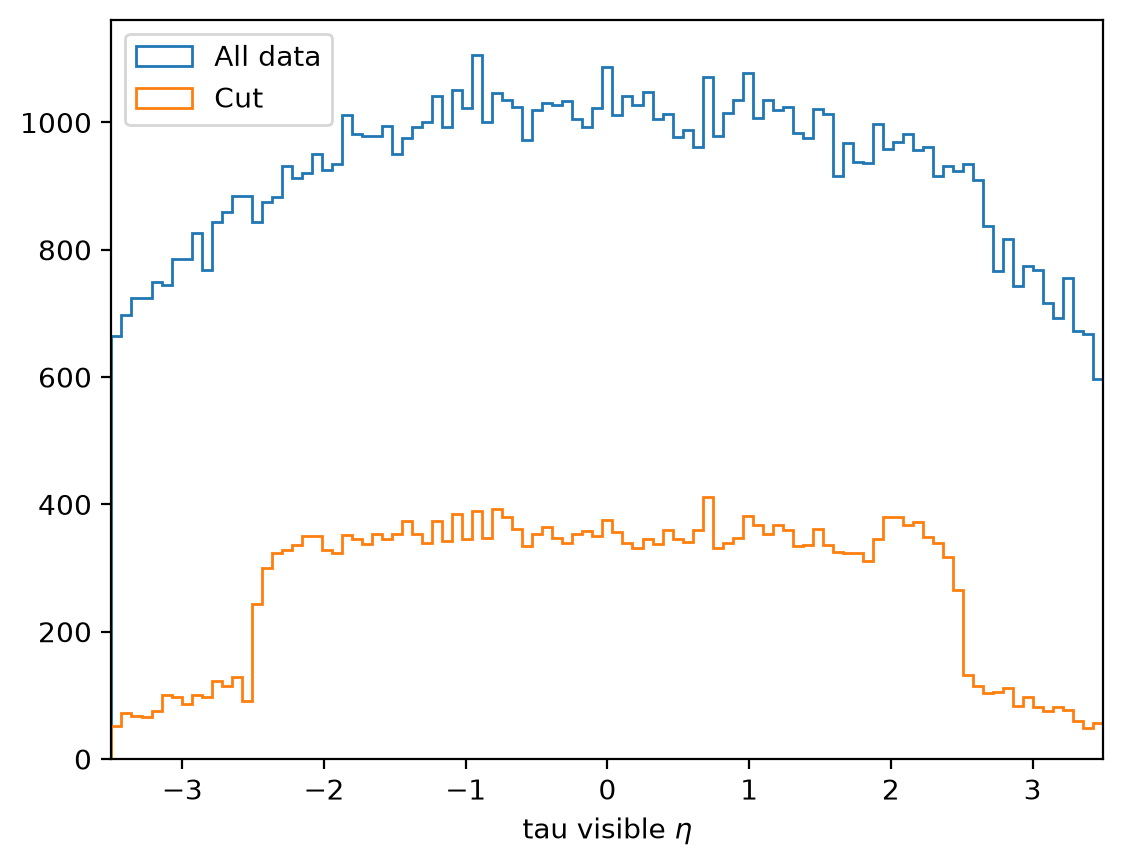

In [ ]:
data_cut = cut(data)
bins=np.arange(0,300,2)
plt.figure(dpi=200)
plt.hist(ak.flatten(data.truth_tau_vis_pt),bins=bins,histtype='step',density=False,label='All data')
plt.hist(ak.flatten(data_cut.truth_tau_vis_pt),bins=bins,histtype='step',density=False,label='Cut')
plt.yscale('log')
plt.xlim(0,200)
plt.xlabel('tau visible pT [GeV]')
plt.legend()

bins_eta=np.linspace(-3.5,3.5,100)
plt.figure(dpi=200)
plt.hist(ak.flatten(data.truth_tau_vis_eta),bins=bins_eta,histtype='step',density=False,label='All data')
plt.hist(ak.flatten(data_cut.truth_tau_vis_eta),bins=bins_eta,histtype='step',density=False,label='Cut')
plt.yscale('linear')
plt.xlim(-3.5,3.5)
plt.xlabel(r'tau visible $\eta$')
plt.legend()

In [ ]:
# tjva_andsumpt2() was split into 3 functions in vtx/analysis.py (same code, reorganized):
#   sumpt2_choice(data, taus)  -> SumPT2 vertex per tau
#   cone_tracks(data, taus)    -> per-tau cone tracks: pt, vtx, dz, eta
#   tjva_v1(cone, sumpt2)      -> your f(v) scoring with the Delphes assignment
#   tjva_v2(cone, data, taus, sumpt2) -> v1 + rescue of unassigned cone tracks (see its docstring)
# tjva_andsumpt2(data, taus) still exists and calls all of them.
data = load_dev(50)
taus = select_taus(data)
sp = sumpt2_choice(data, taus)
cone = cone_tracks(data, taus)
v1, max_f, fallback = tjva_v1(cone, sp)
v2, max_f_v2, fallback_v2, n_rescued = tjva_v2(cone, data, taus, sp)
print(f"fallback rate v1 {fallback.mean():.3f}, v2 {fallback_v2.mean():.3f}; taus with >= 1 rescued cone track {np.mean(n_rescued > 0):.3f}; "
      f"v2 changed the choice for {np.mean(v1 != v2):.3f} of taus")
choices = tjva_andsumpt2(data, taus)
choices.head()

fallback rate v1 0.086, v2 0.061; taus with >= 1 rescued cone track 0.102; v2 changed the choice for 0.025 of taus


,sumpt2_choice,tjva_choice,tjva_v2_choice,max_f,fallback,fallback_v2,n_rescued
0,0,0,0,1.000,False,False,0
1,0,0,0,0.862,False,False,0
2,0,0,0,0.924,False,False,0
3,0,0,0,0.937,False,False,0
4,0,0,0,1.000,False,False,0


In [9]:
# calculate per-tau efficiency for every method, and keep one per-tau table per mu for the plots below
PURITY = 0.0   # 0 = Sebastian's label: the vertex with the most HS tracks (merged vertices allowed)
               # 0.5 =  earlier, stricter label (the HS tracks must also be > 50% of that vertex)
GEN_WINDOW = 0.5  # mm, cross-check: chosen vertex within 0.5 mm of the generator (truth) vertex
methods = {"sumpt2": "sumpt2_choice", "tjva v1": "tjva_choice", "tjva v2": "tjva_v2_choice"}

per_tau = {}
for mu in mu_all:
    data = samples.load(mu, slices=samples.SLICES, columns=COLS)
    taus = select_taus(data)
    choices = tjva_andsumpt2(data, taus=taus)
    ev = taus.event.values

    # one row per tau: what we need to compute efficiencies in any binning later
    taus["slice"] = np.asarray(ak.to_list(data.slice))[ev]
    taus["w"] = samples.event_weights(data)[ev]                              # cross-section weight sigma/N of the tau's slice
    taus["label"] = ak.to_numpy(correct_vertex(data, purity=PURITY))[ev]    # truth label, -1 = no HS vertex
    taus["has_label"] = taus.label >= 0
    taus["fallback"] = choices.fallback.values
    taus["n_rescued"] = choices.n_rescued.values
    truth_z = ak.to_numpy(data.truth_hs_z)[ev]
    for name, col in methods.items():
        choice = choices[col].values
        taus[name] = (choice == taus.label) & taus.has_label                 # -1 == -1 must not count as correct
        taus[name + " gen"] = np.abs(chosen_z(data, taus, choice) - truth_z) < GEN_WINDOW
    taus["hardest track"] = (taus.label == 0)                                # rv_index 0 = vertex seeded by the hardest track
    taus['split'] = samples.split_of(ak.to_numpy(data.event_id)[ev])
    per_tau[mu] = taus

    w = taus.w.values
    print(f"mu = {mu:3d}: ceiling {efficiency(taus.has_label, w)[0]:.3f}, fallback {taus.fallback.mean():.3f}, "
          + ", ".join(f"{m} {efficiency(taus[m], w)[0]:.3f}" for m in ["sumpt2", "hardest track", "tjva v1", "tjva v2"])
          + "   (sigma-weighted, all taus)")
    del data

pd.to_pickle(per_tau, PROJECT / "samples" / "per_tau.pkl")


mu =   0: ceiling 0.998, fallback 0.164, sumpt2 0.988, hardest track 0.976, tjva v1 0.972, tjva v2 0.972   (sigma-weighted, all taus)
mu =  30: ceiling 0.998, fallback 0.102, sumpt2 0.868, hardest track 0.889, tjva v1 0.869, tjva v2 0.888   (sigma-weighted, all taus)
mu =  50: ceiling 0.997, fallback 0.078, sumpt2 0.839, hardest track 0.863, tjva v1 0.839, tjva v2 0.860   (sigma-weighted, all taus)
mu = 100: ceiling 0.998, fallback 0.035, sumpt2 0.802, hardest track 0.832, tjva v1 0.798, tjva v2 0.822   (sigma-weighted, all taus)
mu = 140: ceiling 0.999, fallback 0.022, sumpt2 0.788, hardest track 0.820, tjva v1 0.779, tjva v2 0.803   (sigma-weighted, all taus)
mu = 200: ceiling 0.999, fallback 0.010, sumpt2 0.769, hardest track 0.802, tjva v1 0.767, tjva v2 0.786   (sigma-weighted, all taus)


## Efficiency plots
σ-weighted (each tau carries its slice weight σ/N) unless per slice. "rel. to ceiling" is Sebastian's / THOR definition: the denominator is the taus whose event has an HS vertex.

cross-check, within 0.5 mm of the generator vertex (all taus, σ-weighted):
  mu =   0: sumpt2 0.993, tjva v1 0.992, tjva v2 0.992
  mu =  30: sumpt2 0.873, tjva v1 0.891, tjva v2 0.911
  mu =  50: sumpt2 0.845, tjva v1 0.864, tjva v2 0.885
  mu = 100: sumpt2 0.806, tjva v1 0.825, tjva v2 0.849
  mu = 140: sumpt2 0.792, tjva v1 0.805, tjva v2 0.829
  mu = 200: sumpt2 0.772, tjva v1 0.792, tjva v2 0.813


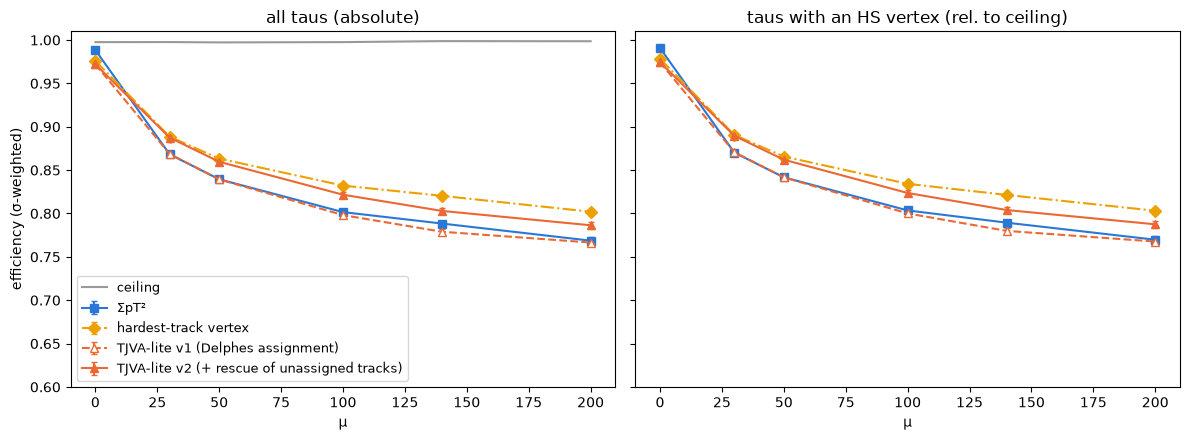

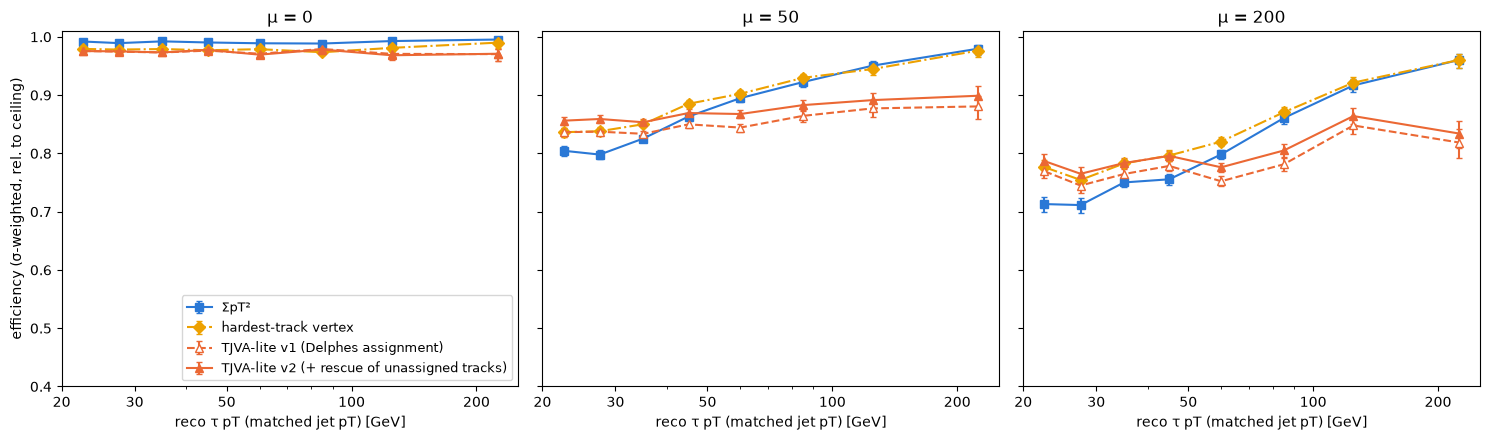

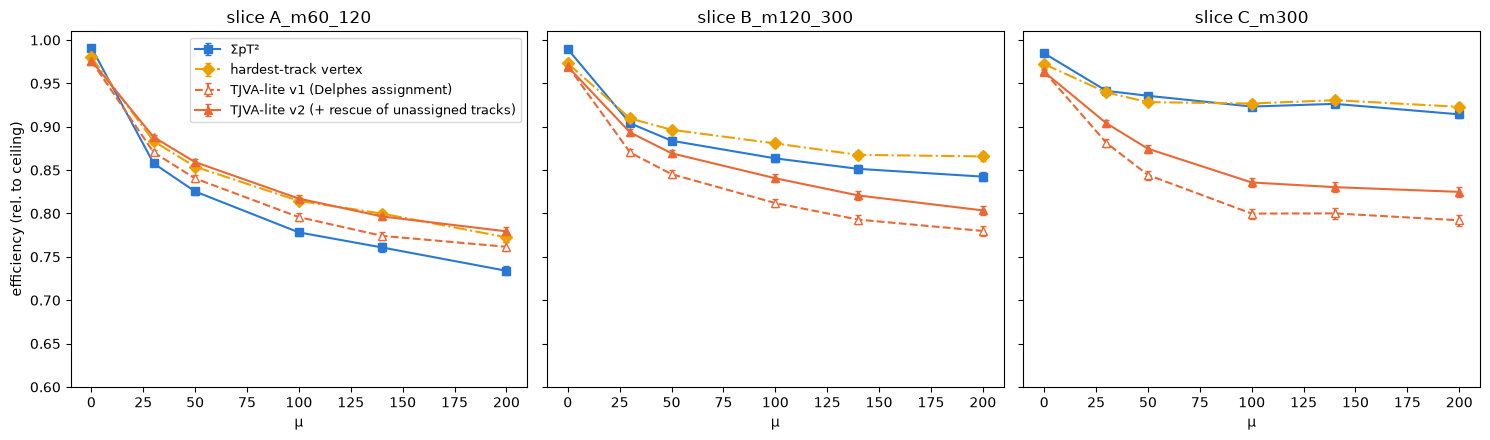

In [ ]:
import matplotlib.ticker

# Efficiency plots from the per-tau tables (per_tau[mu]).
# "rel. to ceiling" = Sebastian's / THOR definition: denominator = taus whose event has an HS vertex.
BLUE, ORANGE, YELLOW, GRAY = "#2a78d6", "#eb6834", "#eda100", "#9a9993"
STYLE = {"sumpt2":        dict(color=BLUE,   marker="s", ls="-",  label="ΣpT²"),
         "hardest track": dict(color=YELLOW, marker="D", ls="-.", label="hardest-track vertex"),
         "tjva v1":       dict(color=ORANGE, marker="^", ls="--", mfc="white", label="TJVA-lite v1 (Delphes assignment)"),
         "tjva v2":       dict(color=ORANGE, marker="^", ls="-",  label="TJVA-lite v2 (+ rescue of unassigned tracks)")}

def plot_eff(ax, x, tables, method, weighted=True, rel_ceiling=True, **kw):
    """One efficiency curve: x values and one per-tau table per x point."""
    effs, los, his = [], [], []
    for t in tables:
        t = t[t.has_label] if rel_ceiling else t
        e, lo, hi = efficiency(t[method], t.w if weighted else None)
        effs.append(e); los.append(lo); his.append(hi)
    effs = np.array(effs)
    ax.errorbar(x, effs, yerr=[effs - los, np.array(his) - effs], ms=6, capsize=2, **{**STYLE.get(method, {}), **kw})

# 1) efficiency vs mu, sigma-weighted: absolute (left) and relative to the ceiling (right)
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, rel in zip(axs, [False, True]):
    for m in STYLE:
        plot_eff(ax, mu_all, [per_tau[mu] for mu in mu_all], m, rel_ceiling=rel)
    if not rel:
        ax.plot(mu_all, [efficiency(per_tau[mu].has_label, per_tau[mu].w)[0] for mu in mu_all], color=GRAY, label="ceiling")
    ax.set(xlabel="μ", title="all taus (absolute)" if not rel else "taus with an HS vertex (rel. to ceiling)")
axs[0].set_ylabel("efficiency (σ-weighted)")
axs[0].legend(fontsize=9)
axs[0].set_ylim(0.6, 1.01)
plt.tight_layout()

# 2) efficiency vs reco tau pT (matched jet pT) at a few mu values, sigma-weighted, rel. to ceiling
pt_bins = np.array([20, 25, 30, 40, 50, 70, 100, 150, 300])
pt_mid = 0.5 * (pt_bins[1:] + pt_bins[:-1])
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, mu in zip(axs, [0, 50, 200]):
    t = per_tau[mu]
    tables = [t[(t.jet_pt >= lo) & (t.jet_pt < hi)] for lo, hi in zip(pt_bins[:-1], pt_bins[1:])]
    for m in STYLE:
        plot_eff(ax, pt_mid, tables, m)
    ax.set(xscale="log", xlabel="reco τ pT (matched jet pT) [GeV]", title=f"μ = {mu}")
    ax.set_xticks([20, 30, 50, 100, 200]); ax.set_xticklabels([20, 30, 50, 100, 200])
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
axs[0].set_ylabel("efficiency (σ-weighted, rel. to ceiling)")
axs[0].set_ylim(0.4, 1.01)
axs[0].legend(fontsize=9, loc="lower right")
plt.tight_layout()

# 3) efficiency vs mu per mass slice (one slice per panel; weights are constant within a slice)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, sl in zip(axs, samples.SLICES):
    for m in STYLE:
        plot_eff(ax, mu_all, [per_tau[mu][per_tau[mu].slice == sl] for mu in mu_all], m, weighted=False)
    ax.set(xlabel="μ", title=f"slice {sl}")
axs[0].set_ylabel("efficiency (rel. to ceiling)")
axs[0].set_ylim(0.6, 1.01)
axs[0].legend(fontsize=9)
plt.tight_layout()

# generator-vertex cross-check (Sebastian): chosen vertex within 0.5 mm of the truth vertex, all taus, sigma-weighted
print("cross-check, within 0.5 mm of the generator vertex (all taus, σ-weighted):")
for mu in mu_all:
    t = per_tau[mu]
    print(f"  mu = {mu:3d}: " + ", ".join(f"{m} {efficiency(t[m + ' gen'], t.w)[0]:.3f}" for m in methods))

In [ ]:
data = load_dev(50)
taus = select_taus(data)

ev = taus.event.values
trk_pts  = data.trk_pt[ev] # per tau, pt of all tracks in this event 
vtx_all  = data.rv_index[ev] # list of candidate vertex index per tau event
sumpt2s  = data.rv_sumpt2[ev] # list of sumpt2 per vertex
vtx_zs   = data.rv_z[ev]

# now make tracks <-> vertex link
trk_vtxs = data.trk_delphes_vtx[ev] #per tau, for each trk, index of associated vertex

# Compare every track's vertex (axis 1) against every event vertex (axis 2)
# Shape: (n_events, var_trks, var_vertices)
matches = trk_vtxs[:, :, None] == vtx_all[:, None, :]
# Count matches along the track axis (axis=1)
n_trks_per_vtx = ak.sum(matches, axis=1) # Shape: (n_events, var_vertices)

# now find maxpT of track associated with vertex
# keep trk_pt where matched, turn non-matches into None -> shape: (n_events, var_trks, var_vertices)
pt_per_vtx = ak.mask(trk_pts[:, :, None], matches)

# take the max along the track axis (axis=1) -> shape: (n_events, var_vertices)
max_trk_pt_per_vtx = ak.max(pt_per_vtx, axis=1)

# find distance to nearest z
z_dists_matrix = np.abs(vtx_zs[:,:,None] - vtx_zs[:,None,:])
idx = ak.local_index(vtx_zs, axis=1)
notselfmask = idx[:, :, None] != idx[:, None, :] #true everywhere except diag of matrix for each event
dz_other = ak.mask(z_dists_matrix,notselfmask)
dz_nearest = ak.min(dz_other,axis=1) # per event, a list of dz to neighbor per vertex

# for each event, now have (ntrks,maxpt,sumpt2,z) per vertex. make a feature vector per vertex
features = [n_trks_per_vtx,max_trk_pt_per_vtx,sumpt2s,dz_nearest]
# swap feature axes so that I have structure [[features of v0, ev0, features v1, ev0, ...],[v0,ev1,...]]
vertex_features = ak.concatenate([f[:, :, None] for f in features], axis=-1)

#n_vtx

#QUESTION: should i only consider vertices with a track pointing to them? 

#features_allv = {}
#for v in vertices:
#    features_thisv = []
#    features_thisv = pd.DataFrame({"nTrks": ,"maxpT": , "sumpt2": ,"nearestz"})
#return tokens

[3.25, 0.83, 0.573, 0.339, 3.9, 3.6, ..., 0.83, 5.34, 3.57, 0.843, 0.792, 0.339]
